# Fase 1: análisis exploratorio del IPC de Argentina (INDEC)

**Proyecto 4:** pronóstico de inflación mensual en Argentina con validación temporal.

**Pregunta de negocio:** ¿con cuánta anticipación y con qué error se puede pronosticar la inflación mensual argentina mejor que con un método ingenuo, y en qué regímenes falla el pronóstico?

**Datos:** `data/raw/serie_ipc_divisiones.csv`, del INDEC, descargado el 2026-11-11. Se procesa con `src/ingest.py` y queda en `data/processed/ipc_divisiones_tidy.csv`.

**Objetivos de este notebook**
1. Comprobar la calidad de los datos.
2. Entender el comportamiento del nivel general nacional.
3. Dejar fijada la definición de regímenes (`src/regimes.py`) **antes** de evaluar ningún modelo.
4. Medir cuántos orígenes de pronóstico habrá disponibles para la validación.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from ingest import SALIDA_POR_DEFECTO, main as ingestar
from regimes import (ETIQUETAS, UMBRAL_BAJA_MEDIA, UMBRAL_MEDIA_ALTA,
                     VENTANA_MESES, regimen)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25})
COLORES_REGIMEN = {"baja": "#9ecae1", "media": "#fdd49e", "alta": "#fb9a99"}
pd.options.display.float_format = "{:,.2f}".format

## 1. Carga y estructura

In [2]:
if not SALIDA_POR_DEFECTO.exists():
    ingestar()  # genera data/processed/ipc_divisiones_tidy.csv desde data/raw/
ipc = pd.read_csv(SALIDA_POR_DEFECTO, parse_dates=["fecha"])

print(f"Filas: {len(ipc):,} | series (código x región): {ipc.serie_id.nunique()} | "
      f"meses: {ipc.fecha.nunique()} ({ipc.fecha.min():%Y-%m} a {ipc.fecha.max():%Y-%m})")
ipc.head()

Filas: 14,868 | series (código x región): 126 | meses: 118 (2016-12 a 2026-09)


,fecha,serie_id,codigo,descripcion,clasificador,region,indice,var_mensual,var_interanual
0,2016-12-01,01|Cuyo,01,Alimentos y bebidas no alcohólicas,Nivel general y divisiones COICOP,Cuyo,100.00,NaN,NaN
1,2017-01-01,01|Cuyo,01,Alimentos y bebidas no alcohólicas,Nivel general y divisiones COICOP,Cuyo,101.45,1.50,NaN
2,2017-02-01,01|Cuyo,01,Alimentos y bebidas no alcohólicas,Nivel general y divisiones COICOP,Cuyo,103.27,1.80,NaN
3,2017-03-01,01|Cuyo,01,Alimentos y bebidas no alcohólicas,Nivel general y divisiones COICOP,Cuyo,105.61,2.30,NaN
4,2017-04-01,01|Cuyo,01,Alimentos y bebidas no alcohólicas,Nivel general y divisiones COICOP,Cuyo,108.66,2.90,NaN


In [3]:
series = (ipc.groupby(["clasificador", "codigo", "descripcion"])
          .agg(regiones=("region", "nunique"), meses=("fecha", "nunique"))
          .reset_index())
series

,clasificador,codigo,descripcion,regiones,meses
0,Bienes y servicios,B,Bienes,7,118
1,Bienes y servicios,S,Servicios,7,118
2,Categorias,Estacional,Estacional,7,118
3,Categorias,Núcleo,Núcleo,7,118
4,Categorias,Regulados,Regulados,7,118
5,Nivel general y divisiones COICOP,0,Nivel general,7,118
6,Nivel general y divisiones COICOP,01,Alimentos y bebidas no alcohólicas,7,118
7,Nivel general y divisiones COICOP,02,Bebidas alcohólicas y tabaco,7,118
8,Nivel general y divisiones COICOP,03,Prendas de vestir y calzado,7,118
9,Nivel general y divisiones COICOP,04,"Vivienda, agua, electricidad, gas y otros comb...",7,118


## 2. Calidad de datos

`src/ingest.py` ya valida la estructura y detiene la ejecución si algo falla: sin duplicados, mismo rango de fechas en todas las series, índice base 100 en diciembre de 2016, y variación mensual publicada consistente con el índice. Acá se muestra qué quedó nulo y por qué.

In [4]:
nulos = ipc[["indice", "var_mensual", "var_interanual"]].isna().sum().to_frame("nulos")
n_series = ipc.serie_id.nunique()
nulos["esperados"] = [0, n_series, n_series * 12]
nulos["explicación"] = ["ninguno", "primer mes de cada serie", "primeros 12 meses de cada serie"]
nulos

,nulos,esperados,explicación
indice,0,0,ninguno
var_mensual,126,126,primer mes de cada serie
var_interanual,1512,1512,primeros 12 meses de cada serie


## 3. Nivel general nacional

Es la serie núcleo del proyecto. La variable a pronosticar es la **variación mensual** (`var_mensual`, en %).

In [5]:
nac = (ipc[(ipc.codigo == "0") & (ipc.region == "Nacional")]
       .set_index("fecha").sort_index())
vm = nac["var_mensual"].dropna()
print(f"Observaciones mensuales: {len(vm)} ({vm.index.min():%Y-%m} a {vm.index.max():%Y-%m})")
vm.describe().to_frame("var_mensual (%)").T

Observaciones mensuales: 117 (2017-01 a 2026-09)


,count,mean,std,min,25%,50%,75%,max
var_mensual (%),117.00,4.27,3.54,1.20,2.30,3.20,4.80,25.50


In [6]:
por_anio = vm.groupby(vm.index.year).agg(["count", "mean", "min", "max"])
por_anio.columns = ["meses", "promedio mensual (%)", "mínimo (%)", "máximo (%)"]
por_anio.index.name = "año"
por_anio

,meses,promedio mensual (%),mínimo (%),máximo (%)
año,,,,
2017,12,1.87,1.20,3.10
2018,12,3.31,1.80,6.50
2019,12,3.67,2.20,5.90
2020,12,2.60,1.50,4.00
2021,12,3.48,2.50,4.80
2022,12,5.72,3.90,7.40
2023,12,10.04,6.00,25.50
2024,12,6.83,2.40,20.60
2025,12,2.31,1.50,3.70


## 4. Regímenes de inflación

**Definición fijada en esta fase** (código en `src/regimes.py`):
- El régimen en una fecha se define por el **promedio de los últimos 3 meses** de la variación mensual, usando solo información disponible hasta esa fecha.
- **Baja:** menos de 3 % mensual (unos 43 % anual). **Media:** de 3 % a menos de 6 % (hasta unos 101 % anual). **Alta:** 6 % o más.
- En la evaluación, cada pronóstico se etiqueta con el régimen vigente en su fecha de origen.

Estos umbrales se eligieron mirando la serie completa, **antes de evaluar cualquier modelo**, y no se cambian después de ver resultados.

In [7]:
reg = regimen(vm)

resumen_reg = (reg.value_counts().reindex(list(ETIQUETAS)).to_frame("meses")
               .assign(porcentaje=lambda x: 100 * x.meses / x.meses.sum()))
display(resumen_reg)
print(f"Meses sin etiqueta por falta de historia: {int(reg.isna().sum())}")

# Tramos consecutivos de cada régimen
r = reg.dropna()
tramo = (r != r.shift()).cumsum()
tramos = (pd.DataFrame({"régimen": r, "tramo": tramo}).reset_index()
          .groupby("tramo").agg(régimen=("régimen", "first"), desde=("fecha", "min"),
                                hasta=("fecha", "max"), meses=("fecha", "size")))
tramos["desde"] = tramos["desde"].dt.strftime("%Y-%m")
tramos["hasta"] = tramos["hasta"].dt.strftime("%Y-%m")
print(f"Cambios de régimen: {len(tramos) - 1}")
tramos.reset_index(drop=True)

,meses,porcentaje
var_mensual,,
baja,51,44.35
media,46,40.00
alta,18,15.65


Meses sin etiqueta por falta de historia: 2
Cambios de régimen: 16


,régimen,desde,hasta,meses
0,baja,2017-03,2018-07,17
1,media,2018-08,2018-12,5
2,baja,2019-01,2019-01,1
3,media,2019-02,2019-06,5
4,baja,2019-07,2019-08,2
5,media,2019-09,2020-01,5
6,baja,2020-02,2020-09,8
7,media,2020-10,2021-07,10
8,baja,2021-08,2021-08,1
9,media,2021-09,2022-07,11


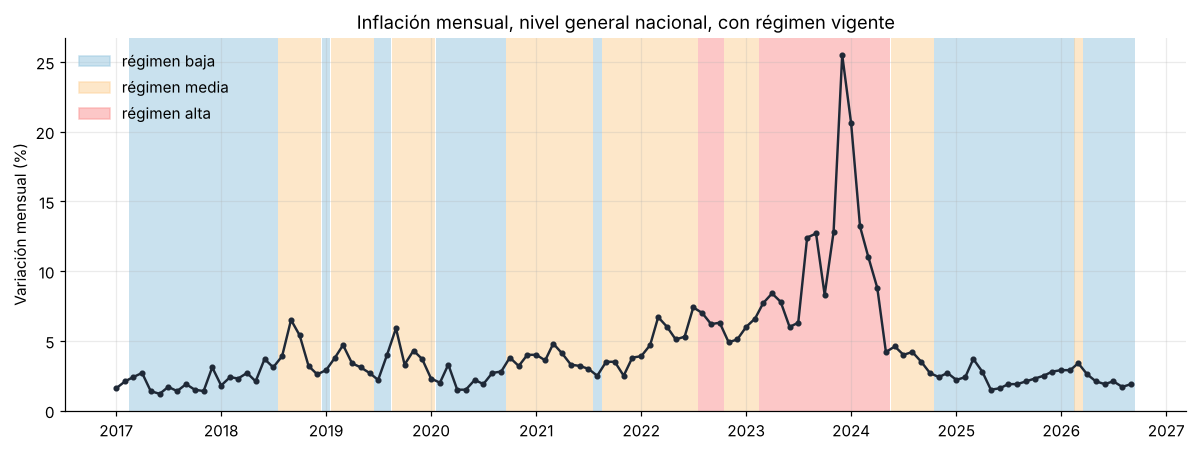

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for _, t in tramos.iterrows():
    ini = pd.Timestamp(t["desde"]) - pd.Timedelta(days=15)
    fin = pd.Timestamp(t["hasta"]) + pd.Timedelta(days=15)
    ax.axvspan(ini, fin, color=COLORES_REGIMEN[t["régimen"]], alpha=0.55, lw=0)
ax.plot(vm.index, vm.values, color="#1f2937", lw=1.6, marker="o", ms=3)
ax.set_title("Inflación mensual, nivel general nacional, con régimen vigente")
ax.set_ylabel("Variación mensual (%)")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORES_REGIMEN[k], alpha=0.55) for k in ETIQUETAS]
ax.legend(handles, [f"régimen {k}" for k in ETIQUETAS], loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

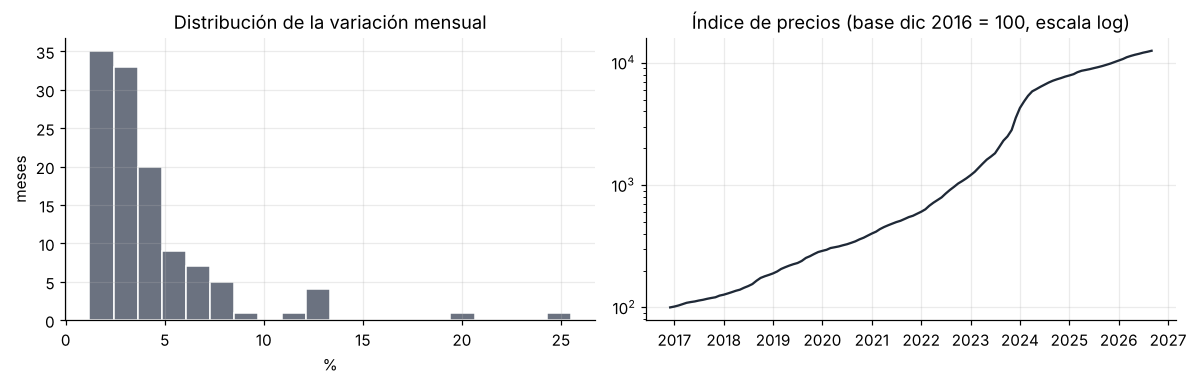

Asimetría: 3.29 | mediana 3.2 % vs promedio 4.3 %


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(vm, bins=20, color="#6b7280", edgecolor="white")
axes[0].set_title("Distribución de la variación mensual")
axes[0].set_xlabel("%"); axes[0].set_ylabel("meses")
axes[1].plot(nac.index, nac["indice"], color="#1f2937")
axes[1].set_yscale("log")
axes[1].set_title("Índice de precios (base dic 2016 = 100, escala log)")
plt.tight_layout(); plt.show()

print(f"Asimetría: {vm.skew():.2f} | mediana {vm.median():.1f} % vs promedio {vm.mean():.1f} %")

## 5. Estacionalidad

Se compara cada mes con el promedio de su año, usando la **mediana** de los desvíos para que un mes extremo no domine. Se usan solo los años completos (2017 a 2025).

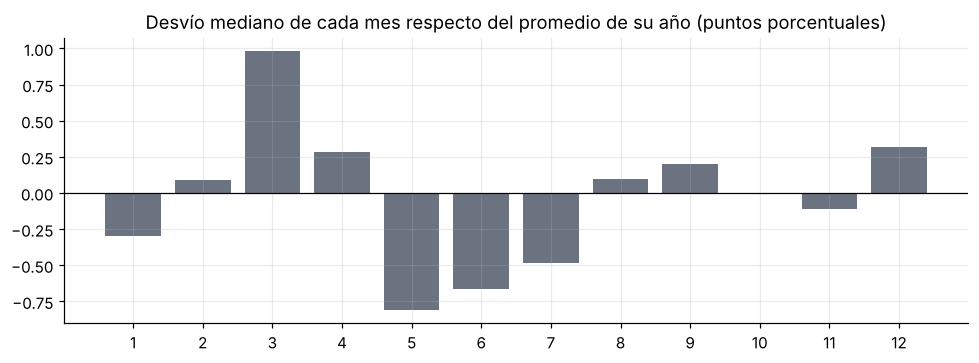

Solo hay 9 observaciones por mes y los regímenes cambian entre años: es un indicio, no una conclusión.


In [10]:
completos = vm[(vm.index.year >= 2017) & (vm.index.year <= 2025)]
desvio = completos - completos.groupby(completos.index.year).transform("mean")
estacional = desvio.groupby(desvio.index.month).median()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(estacional.index, estacional.values, color="#6b7280")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(1, 13))
ax.set_title("Desvío mediano de cada mes respecto del promedio de su año (puntos porcentuales)")
plt.tight_layout(); plt.show()
print("Solo hay 9 observaciones por mes y los regímenes cambian entre años: es un indicio, no una conclusión.")

## 6. Autocorrelación y estacionariedad

La serie tiene **memoria fuerte**: lo que pasó el mes anterior explica buena parte del siguiente. Eso es lo que usa el baseline ingenuo.

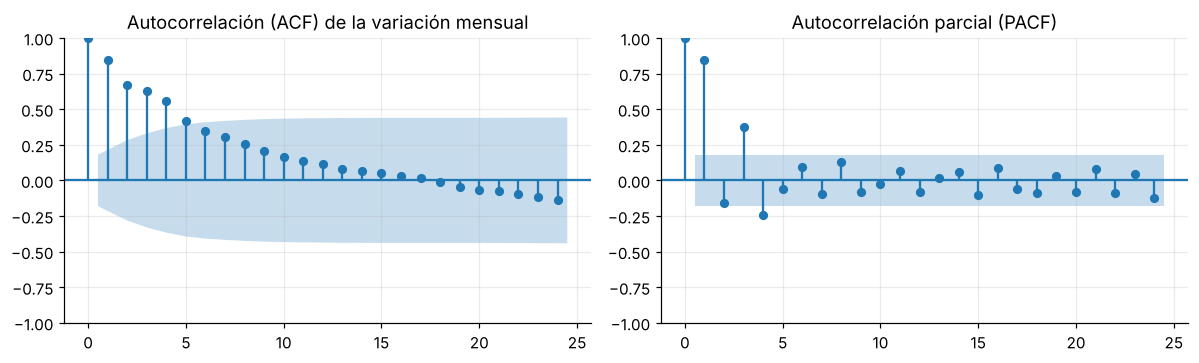

Autocorrelación en rezagos 1, 2, 3, 6 y 12: [0.85, 0.67, 0.63, 0.35, 0.12]
Prueba ADF sobre variación mensual: p-valor = 0.074
Prueba ADF sobre primera diferencia: p-valor = 0.000


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
plot_acf(vm, lags=24, ax=axes[0], title="Autocorrelación (ACF) de la variación mensual")
plot_pacf(vm, lags=24, ax=axes[1], method="ywm", title="Autocorrelación parcial (PACF)")
plt.tight_layout(); plt.show()

aut = [vm.autocorr(k) for k in (1, 2, 3, 6, 12)]
print("Autocorrelación en rezagos 1, 2, 3, 6 y 12:", [round(float(a), 2) for a in aut])

import warnings
for nombre, serie in [("variación mensual", vm), ("primera diferencia", vm.diff().dropna())]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        p = adfuller(serie, regression="c", autolag="AIC")[1]
    print(f"Prueba ADF sobre {nombre}: p-valor = {p:.3f}")

La prueba ADF busca raíz unitaria y con unas 117 observaciones y un quiebre de régimen tiene poca potencia. **No se usa para decidir la transformación**: eso se define en la Fase 2 comparando errores de validación.

## 7. Regiones y divisiones

Estas series alimentan el modelo global sobre el panel (Fase 3).

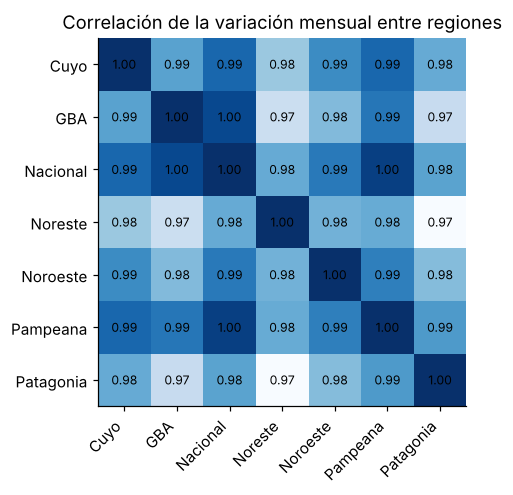

Correlación mínima entre regiones: 0.97


In [12]:
gral = ipc[ipc.codigo == "0"].pivot(index="fecha", columns="region", values="var_mensual").dropna()
corr = gral.corr()

fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(corr.values, vmin=corr.values.min(), vmax=1, cmap="Blues")
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
ax.set_title("Correlación de la variación mensual entre regiones")
plt.tight_layout(); plt.show()
print(f"Correlación mínima entre regiones: {corr.values[np.triu_indices(len(corr), 1)].min():.2f}")

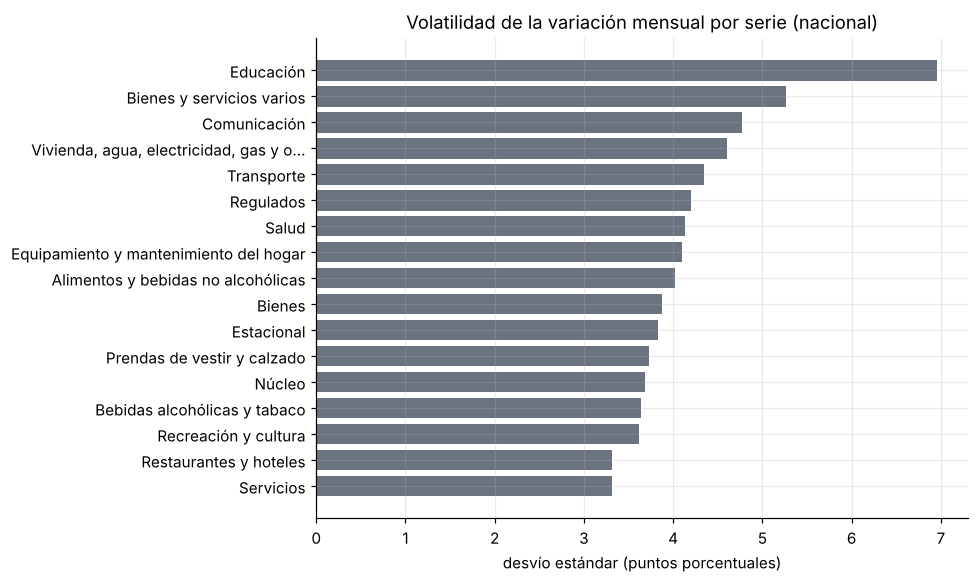

promedio (%)  \
clasificador                      descripcion                                                        
Nivel general y divisiones COICOP Educación                                                   4.36   
                                  Bienes y servicios varios                                   4.29   
                                  Comunicación                                                4.26   
                                  Vivienda, agua, electricidad, gas y otros combu...          4.42   
                                  Transporte                                                  4.34   
Categorias                        Regulados                                                   4.34   
Nivel general y divisiones COICOP Salud                                                       4.40   
                                  Equipamiento y mantenimiento del hogar                      4.08   
                                  Alimentos y bebidas no alcohólicas                          4.35   
Bienes y servicios                Bienes                                                      4.26   
Categorias                        Estacional                                                  4.11   
Nivel general y divisiones COICOP Prendas de vestir y calzado                                 3.91   
Categorias                        Núcleo                                                      4.28   
Nivel general y divisiones COICOP Bebidas alcohólicas y tabaco                                3.94   
                                  Recreación y cultura                                        4.18   
                                  Restaurantes y hoteles                                      4.45   
Bienes y servicios                Servicios                                                   4.31   

                                                                                      desvío estándar (pp)  \
clasificador                      descripcion                                                                
Nivel general y divisiones COICOP Educación                                                           6.96   
                                  Bienes y servicios varios                                           5.26   
                                  Comunicación                                                        4.77   
                                  Vivienda, agua, electricidad, gas y otros combu...                  4.61   
                                  Transporte                                                          4.35   
Categorias                        Regulados                                                           4.20   
Nivel general y divisiones COICOP Salud                                                               4.13   
                                  Equipamiento y mantenimiento del hogar                              4.10   
                                  Alimentos y bebidas no alcohólicas                                  4.03   
Bienes y servicios                Bienes                                                              3.88   
Categorias                        Estacional                                                          3.83   
Nivel general y divisiones COICOP Prendas de vestir y calzado                                         3.73   
Categorias                        Núcleo                                                              3.68   
Nivel general y divisiones COICOP Bebidas alcohólicas y tabaco                                        3.64   
                                  Recreación y cultura                                                3.62   
                                  Restaurantes y hoteles                                              3.31   
Bienes y servicios                Servicios                                                           3.31   

                                                        

In [13]:
resto = ipc[(ipc.region == "Nacional") & (ipc.codigo != "0")]
volatilidad = (resto.groupby(["clasificador", "descripcion"]).var_mensual
               .agg(["mean", "std", "max"]).sort_values("std", ascending=False))
volatilidad.columns = ["promedio (%)", "desvío estándar (pp)", "máximo (%)"]

fig, ax = plt.subplots(figsize=(9, 5.4))
etiquetas = [d if len(d) <= 40 else d[:37] + "..." for _, d in volatilidad.index]
ax.barh(etiquetas[::-1], volatilidad["desvío estándar (pp)"].values[::-1], color="#6b7280")
ax.set_title("Volatilidad de la variación mensual por serie (nacional)")
ax.set_xlabel("desvío estándar (puntos porcentuales)")
plt.tight_layout(); plt.show()
volatilidad

## 8. Cuántos pronósticos se pueden evaluar

Con una ventana inicial de entrenamiento de 36 meses, estos son los orígenes disponibles para la validación de origen móvil en cada horizonte (nivel general nacional).

In [14]:
VENTANA_INICIAL = 36
n = len(vm)
orig = pd.DataFrame({"horizonte (meses)": [1, 3, 6]})
orig["orígenes disponibles"] = n - VENTANA_INICIAL - orig["horizonte (meses)"] + 1
for e in ETIQUETAS:
    orig[e] = 0

reg_obj = regimen(vm)
primer_origen = VENTANA_INICIAL - 1  # posición del último dato de entrenamiento
for h in (1, 3, 6):
    etiquetas_origen = reg_obj.iloc[primer_origen: n - h]
    cuenta = etiquetas_origen.value_counts().reindex(list(ETIQUETAS))
    for e in ETIQUETAS:
        orig.loc[orig["horizonte (meses)"] == h, e] = int(cuenta[e])
orig

,horizonte (meses),orígenes disponibles,baja,media,alta
0,1,81,30,33,18
1,3,79,28,33,18
2,6,76,25,33,18


## 9. Conclusiones de la Fase 1

- **Datos:** estructura válida y consistente. Los nulos están solo donde corresponde (primer mes y primeros 12 meses de cada serie).
- **Regímenes fijados:** baja, media y alta según el promedio móvil de 3 meses, con umbrales de 3 % y 6 % mensual (`src/regimes.py`).
- **Memoria de la serie:** la autocorrelación es alta en los primeros rezagos, así que el baseline ingenuo será exigente.
- **Limitación principal para las fases siguientes:** el régimen **alto** tiene pocos meses. Los errores por régimen en ese tramo van a tener mucha incertidumbre y hay que reportarlos con ese límite explícito.